## 1. Carga y limpieza de los datos

Dataset: siniestros viales de CABA (2019–sept. 2025), data.buenosaires.gob.ar. Se parte del archivo de **hechos** (65.818 filas). Primer paso: sacar del medio un error de exportación de Excel (`#¡REF!`) que quedó en una fila del campo `modo_desplazamiento_victima`, antes de tocar cualquier otra cosa.

In [1]:
import pandas as pd

hechos = pd.read_csv('../data/siniestros_viales_hechos.csv', encoding='utf-8-sig', sep=';', low_memory=False)
victimas = pd.read_csv('../data/siniestros_viales_victimas.csv', encoding='utf-8-sig', sep=';', low_memory=False)

print('Hechos:', hechos.shape)
print('Víctimas:', victimas.shape)

Hechos: (65818, 21)
Víctimas: (75197, 9)


In [2]:
hechos = hechos[hechos['modo_desplazamiento_victima'] != '#¡REF!'].copy()

columnas_texto_hechos = ['modo_desplazamiento_victima', 'gravedad_siniestro', 'tipo_de_via_siniestro']
for col in columnas_texto_hechos:
    hechos[col] = hechos[col].str.strip().str.upper()

columnas_texto_victimas = ['modo_desplazamiento_victima', 'GRAVEdad_victima', 'rol_victima']
for col in columnas_texto_victimas:
    victimas[col] = victimas[col].str.strip().str.upper()

print(hechos['modo_desplazamiento_victima'].value_counts())

modo_desplazamiento_victima
MOTO                  24555
SD                    10928
PEATON                 9415
BICICLETA              7091
AUTO                   7073
TRANSPORTE PUBLICO     3633
TAXI                    810
UTILITARIO              697
MOVIL                   531
MIXTO                   498
CAMION                  250
MONOPATIN               207
OTRO                    129
Name: count, dtype: int64


In [3]:
import re

def normalizar_comuna(valor):
    if pd.isna(valor):
        return None
    match = re.search(r'\d+', str(valor))
    return int(match.group()) if match else None

hechos['comuna'] = hechos['comuna_siniestro'].apply(normalizar_comuna)
print(hechos['comuna'].value_counts().sort_index())

comuna
1.0     7241
2.0     2350
3.0     4858
4.0     4562
5.0     3285
6.0     2772
7.0     4368
8.0     3088
9.0     4450
10.0    3776
11.0    3531
12.0    4310
13.0    3965
14.0    4496
15.0    5214
Name: count, dtype: int64


In [4]:
hechos_geo = hechos.dropna(subset=['latitud_siniestro', 'longitud_siniestro']).copy()
hechos_geo['latitud_siniestro'] = hechos_geo['latitud_siniestro'].astype(float)
hechos_geo['longitud_siniestro'] = hechos_geo['longitud_siniestro'].astype(float)

print(f'{len(hechos_geo)} de {len(hechos)} siniestros tienen coordenadas ({len(hechos_geo)/len(hechos)*100:.1f}%)')hechos_geo = hechos.dropna(subset=['latitud_siniestro', 'longitud_siniestro']).copy()
hechos_geo['latitud_siniestro'] = hechos_geo['latitud_siniestro'].astype(float)
hechos_geo['longitud_siniestro'] = hechos_geo['longitud_siniestro'].astype(float)

print(f'{len(hechos_geo)} de {len(hechos)} siniestros tienen coordenadas ({len(hechos_geo)/len(hechos)*100:.1f}%)')

SyntaxError: invalid syntax (1679950593.py, line 5)

In [ ]:
hechos_geo = hechos.dropna(subset=['latitud_siniestro', 'longitud_siniestro']).copy()
hechos_geo['latitud_siniestro'] = hechos_geo['latitud_siniestro'].astype(float)
hechos_geo['longitud_siniestro'] = hechos_geo['longitud_siniestro'].astype(float)

print(f'{len(hechos_geo)} de {len(hechos)} siniestros tienen coordenadas ({len(hechos_geo)/len(hechos)*100:.1f}%)')

In [ ]:
hechos_geo = hechos.copy()
hechos_geo['latitud_siniestro'] = pd.to_numeric(hechos_geo['latitud_siniestro'], errors='coerce')
hechos_geo['longitud_siniestro'] = pd.to_numeric(hechos_geo['longitud_siniestro'], errors='coerce')
hechos_geo = hechos_geo.dropna(subset=['latitud_siniestro', 'longitud_siniestro']).copy()

print(f'{len(hechos_geo)} de {len(hechos)} siniestros tienen coordenadas ({len(hechos_geo)/len(hechos)*100:.1f}%)')

Con las columnas de texto ya normalizadas y las coordenadas válidas filtradas, nos quedamos solo con los siniestros donde la víctima se desplazaba en **moto** — esa es la base de trabajo de toda la tesis (23.343 casos).

In [ ]:
motos = hechos_geo[hechos_geo['modo_desplazamiento_victima'] == 'MOTO'].copy()
print(f'{len(motos)} siniestros de motociclistas con coordenadas válidas')
print()
print(motos['gravedad_siniestro'].value_counts())

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(motos['longitud_siniestro'], motos['latitud_siniestro'], s=2, alpha=0.3, c='crimson')
ax.set_title(f'Siniestros de motociclistas en CABA ({len(motos)} puntos)')
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
plt.show()

In [ ]:
motos.to_csv('../data/motos_limpio.csv', index=False)
print('Guardado en data/motos_limpio.csv')

## 2. Identificación de hotspots (DBSCAN)

**Primer intento: 300 metros de radio, mínimo 8 casos.** La idea era agrupar puntos geográficamente cercanos para encontrar zonas de concentración real de siniestros, no solo puntos aislados.

In [ ]:
from sklearn.cluster import DBSCAN
import numpy as np

# DBSCAN con distancia haversine necesita las coordenadas en radianes
coords = motos[['latitud_siniestro', 'longitud_siniestro']].values
coords_rad = np.radians(coords)

# eps en radianes: 300 metros / radio de la Tierra en metros
eps_metros = 300
eps_rad = eps_metros / 6371000

db = DBSCAN(eps=eps_rad, min_samples=8, metric='haversine').fit(coords_rad)
motos['cluster'] = db.labels_

n_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
n_ruido = list(db.labels_).count(-1)

print(f'{n_clusters} hotspots encontrados')
print(f'{n_ruido} siniestros aislados (sin hotspot cercano) de {len(motos)}')

**Resultado del primer intento: falló.** Con 300m de radio, DBSCAN sufre el efecto de "encadenamiento" típico en zonas urbanas densas — en vez de encontrar zonas puntuales, terminó fusionando casi toda la ciudad en un solo cluster gigante (ver el tamaño del cluster más grande abajo). No es un hotspot útil, es la ciudad entera.

In [ ]:
tamanos = motos[motos['cluster'] != -1]['cluster'].value_counts().sort_values(ascending=False)
print(tamanos)

**Ajuste que resolvió el problema: 60 metros (~una cuadra), mínimo 10 casos por cluster.** A esa escala, los clusters quedan geográficamente coherentes en vez de fusionarse. Resultado: 430 hotspots reales, con ~68% de los siniestros clasificados como "aislados" (sin recurrencia puntual) — un resultado esperable, no todo punto de la ciudad concentra siniestralidad repetida.

In [ ]:
eps_metros = 60  # ~una cuadra
min_muestras = 10  # al menos 10 siniestros históricos para considerarlo un hotspot real

eps_rad = eps_metros / 6371000
db = DBSCAN(eps=eps_rad, min_samples=min_muestras, metric='haversine').fit(coords_rad)
motos['cluster'] = db.labels_

n_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
n_ruido = list(db.labels_).count(-1)

print(f'{n_clusters} hotspots encontrados')
print(f'{n_ruido} siniestros aislados de {len(motos)} ({n_ruido/len(motos)*100:.1f}%)')
print()
tamanos = motos[motos['cluster'] != -1]['cluster'].value_counts().sort_values(ascending=False)
print(tamanos.head(15))

In [ ]:
fig, ax = plt.subplots(figsize=(9, 9))

ruido = motos[motos['cluster'] == -1]
en_cluster = motos[motos['cluster'] != -1]

ax.scatter(ruido['longitud_siniestro'], ruido['latitud_siniestro'], s=2, alpha=0.15, c='gray', label='Aislados')
ax.scatter(en_cluster['longitud_siniestro'], en_cluster['latitud_siniestro'], s=6, alpha=0.6, c='crimson', label='En hotspot')

ax.set_title(f'Hotspots detectados (430) vs. siniestros aislados')
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.legend()
plt.show()

In [ ]:
motos.to_csv('../data/motos_con_clusters.csv', index=False)

hotspots_resumen = motos[motos['cluster'] != -1].groupby('cluster').agg(
    latitud=('latitud_siniestro', 'mean'),
    longitud=('longitud_siniestro', 'mean'),
    cantidad_siniestros=('cluster', 'count'),
    mortales=('gravedad_siniestro', lambda x: (x == 'MORTAL').sum()),
    graves=('gravedad_siniestro', lambda x: (x == 'GRAVE').sum()),
).reset_index().sort_values('cantidad_siniestros', ascending=False)

hotspots_resumen.to_csv('../data/hotspots_moto_caba.csv', index=False)
print(f'{len(hotspots_resumen)} hotspots guardados')
print()
print(hotspots_resumen.head(10))

Geocodificación inversa (Nominatim) de los hotspots con más casos, para poder referenciarlos por nombre de calle en el análisis y no solo por coordenadas.

In [ ]:
import requests
import time

def geocodificar_inverso(lat, lng):
    url = f'https://nominatim.openstreetmap.org/reverse?lat={lat}&lon={lng}&format=json&accept-language=es'
    r = requests.get(url, headers={'User-Agent': 'MotoSafeGBA-Tesis/1.0'})
    data = r.json()
    return data.get('display_name', 'Sin dirección')

top10 = hotspots_resumen.head(10).copy()
direcciones = []
for _, fila in top10.iterrows():
    direcciones.append(geocodificar_inverso(fila['latitud'], fila['longitud']))
    time.sleep(1)  # Nominatim pide no golpear más de 1 request por segundo

top10['direccion'] = direcciones
print(top10[['cluster', 'cantidad_siniestros', 'mortales', 'graves', 'direccion']].to_string())

## 3. Modelo predictivo — versión 1 (solo contexto del siniestro)

Se retoma desde el CSV limpio para dejar el modelado como una sección independiente y reproducible. Variable objetivo: gravedad del siniestro (`LEVE` / `GRAVE` / `MORTAL`), con fuerte desbalance de clases (93% / 6% / 1%).

In [ ]:
import pandas as pd

motos = pd.read_csv('../data/motos_limpio.csv')
print(motos.shape)
motos.head()

In [ ]:
print(motos.columns.tolist())

In [ ]:
print('=== hora_siniestro (muestra) ===')
print(motos['hora_siniestro'].unique()[:15])
print()
print('=== contraparte_siniestro ===')
print(motos['contraparte_siniestro'].value_counts())
print()
print('=== tipo_de_via_siniestro ===')
print(motos['tipo_de_via_siniestro'].value_counts())
print()
print('=== gravedad_siniestro (nuestro objetivo a predecir) ===')
print(motos['gravedad_siniestro'].value_counts())

In [ ]:
# Normalizar mayúsculas en las columnas de texto que vamos a usar
motos['contraparte_siniestro'] = motos['contraparte_siniestro'].str.strip().str.upper()
motos['tipo_de_via_siniestro'] = motos['tipo_de_via_siniestro'].str.strip().str.upper()

# Extraer hora (0-23) y día de la semana de las columnas de fecha/hora
motos['hora'] = pd.to_datetime(motos['hora_siniestro'], format='%H:%M:%S').dt.hour
motos['dia_semana'] = pd.to_datetime(motos['fecha_siniestro']).dt.day_name()

print(motos['contraparte_siniestro'].value_counts())
print()
print(motos[['hora', 'dia_semana']].head())

Variables predictoras de esta primera versión: hora, día de la semana, comuna, tipo de vía y contraparte del siniestro — nada sobre la víctima todavía. Se codifican con one-hot encoding.

In [ ]:
columnas_categoricas = ['dia_semana', 'comuna_siniestro', 'tipo_de_via_siniestro', 'contraparte_siniestro']

# Sacamos las pocas filas sin hora válida antes de construir las variables
motos_modelo = motos.dropna(subset=['hora']).copy()

X = pd.get_dummies(motos_modelo[['hora'] + columnas_categoricas], columns=columnas_categoricas)
y = motos_modelo['gravedad_siniestro']

print('Filas usables para el modelo:', len(motos_modelo))
print('Cantidad de variables predictoras después de codificar categorías:', X.shape[1])
print()
print('Distribución del objetivo (lo que el modelo va a predecir):')
print(y.value_counts())

Random Forest con `class_weight='balanced'` para compensar el desbalance de clases (si no, el modelo aprende a predecir casi siempre "LEVE" y listo, porque es el 93% de los casos).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Entrenamiento: {len(X_train)} filas')
print(f'Prueba: {len(X_test)} filas')

modelo = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    class_weight='balanced',  # compensa que MORTAL es solo el 1.2% de los casos
    random_state=42,
    n_jobs=-1
)
modelo.fit(X_train, y_train)
print('Modelo entrenado.')

Evaluación con `classification_report` y matriz de confusión — no `accuracy`, porque con este desbalance el accuracy miente (un modelo que predijera siempre LEVE ya tendría 93% de accuracy sin haber aprendido nada útil sobre GRAVE o MORTAL).

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = modelo.predict(X_test)

print(classification_report(y_test, y_pred))

matriz = confusion_matrix(y_test, y_pred, labels=['LEVE', 'GRAVE', 'MORTAL'])
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=['LEVE', 'GRAVE', 'MORTAL'],
            yticklabels=['LEVE', 'GRAVE', 'MORTAL'], ax=ax)
ax.set_xlabel('Predicción del modelo')
ax.set_ylabel('Realidad')
ax.set_title('Matriz de confusión')
plt.show()

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = modelo.predict(X_test)

print(classification_report(y_test, y_pred))

matriz = confusion_matrix(y_test, y_pred, labels=['LEVE', 'GRAVE', 'MORTAL'])
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=['LEVE', 'GRAVE', 'MORTAL'],
            yticklabels=['LEVE', 'GRAVE', 'MORTAL'], ax=ax)
ax.set_xlabel('Predicción del modelo')
ax.set_ylabel('Realidad')
ax.set_title('Matriz de confusión')
plt.show()

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = modelo.predict(X_test)

print(classification_report(y_test, y_pred))

matriz = confusion_matrix(y_test, y_pred, labels=['LEVE', 'GRAVE', 'MORTAL'])
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=['LEVE', 'GRAVE', 'MORTAL'],
            yticklabels=['LEVE', 'GRAVE', 'MORTAL'], ax=ax)
ax.set_xlabel('Predicción del modelo')
ax.set_ylabel('Realidad')
ax.set_title('Matriz de confusión')
plt.show()

In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# --- Carga y limpieza ---
motos = pd.read_csv('../data/motos_limpio.csv')
motos['contraparte_siniestro'] = motos['contraparte_siniestro'].str.strip().str.upper()
motos['tipo_de_via_siniestro'] = motos['tipo_de_via_siniestro'].str.strip().str.upper()
motos['hora'] = pd.to_datetime(motos['hora_siniestro'], format='%H:%M:%S').dt.hour
motos['dia_semana'] = pd.to_datetime(motos['fecha_siniestro']).dt.day_name()
motos_modelo = motos.dropna(subset=['hora']).copy()

# --- Variables ---
columnas_categoricas = ['dia_semana', 'comuna_siniestro', 'tipo_de_via_siniestro', 'contraparte_siniestro']
X = pd.get_dummies(motos_modelo[['hora'] + columnas_categoricas], columns=columnas_categoricas)
y = motos_modelo['gravedad_siniestro']

# --- Entrenamiento ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
modelo = RandomForestClassifier(n_estimators=200, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1)
modelo.fit(X_train, y_train)
print('Modelo entrenado con', len(X_train), 'filas.')

# --- Evaluación ---
y_pred = modelo.predict(X_test)
print(classification_report(y_test, y_pred))

matriz = confusion_matrix(y_test, y_pred, labels=['LEVE', 'GRAVE', 'MORTAL'])
fi

Modelo entrenado con 18670 filas.
              precision    recall  f1-score   support

       GRAVE       0.09      0.12      0.10       260
        LEVE       0.94      0.88      0.91      4352
      MORTAL       0.08      0.39      0.13        56

    accuracy                           0.83      4668
   macro avg       0.37      0.46      0.38      4668
weighted avg       0.89      0.83      0.86      4668



NameError: name 'fi' is not defined

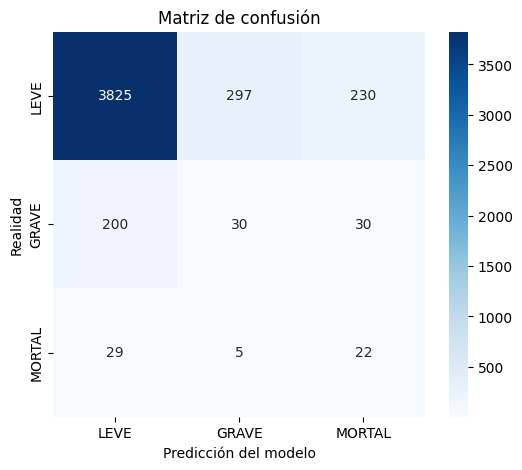

In [6]:
matriz = confusion_matrix(y_test, y_pred, labels=['LEVE', 'GRAVE', 'MORTAL'])
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=['LEVE', 'GRAVE', 'MORTAL'],
            yticklabels=['LEVE', 'GRAVE', 'MORTAL'], ax=ax)
ax.set_xlabel('Predicción del modelo')
ax.set_ylabel('Realidad')
ax.set_title('Matriz de confusión')
plt.show()

Importancia de variables del modelo base: sirve para entender qué explica la gravedad antes de agregar nada sobre la víctima.

                                    variable  importancia
0                                       hora     0.182477
45                contraparte_siniestro_AUTO     0.098476
47              contraparte_siniestro_CAMION     0.084600
40           tipo_de_via_siniestro_AUTOPISTA     0.068414
53         contraparte_siniestro_OBJETO FIJO     0.055166
42             tipo_de_via_siniestro_AVENIDA     0.034637
43               tipo_de_via_siniestro_CALLE     0.025333
58  contraparte_siniestro_TRANSPORTE PUBLICO     0.024044
56                  contraparte_siniestro_SD     0.022620
3                        dia_semana_Saturday     0.021215
5                        dia_semana_Thursday     0.019905
7                       dia_semana_Wednesday     0.019904
1                          dia_semana_Friday     0.018437
6                         dia_semana_Tuesday     0.017117
2                          dia_semana_Monday     0.016754


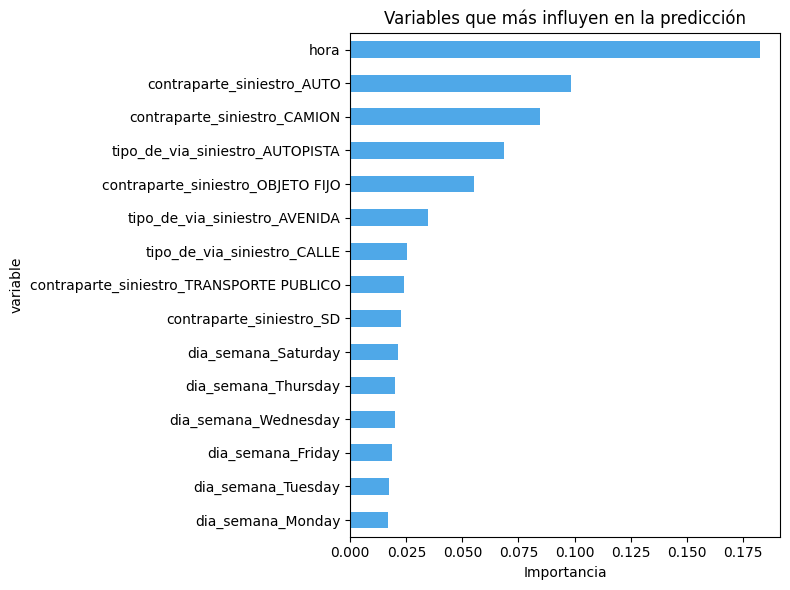

In [7]:
importancias = pd.DataFrame({
    'variable': X.columns,
    'importancia': modelo.feature_importances_
}).sort_values('importancia', ascending=False)

print(importancias.head(15))

fig, ax = plt.subplots(figsize=(8, 6))
importancias.head(15).plot.barh(x='variable', y='importancia', ax=ax, legend=False, color='#4FA8E8')
ax.invert_yaxis()
ax.set_title('Variables que más influyen en la predicción')
ax.set_xlabel('Importancia')
plt.tight_layout()
plt.show()

**Prueba adicional:** ¿mejora el modelo si simplificamos el problema a binario (LEVE vs. GRAVE+MORTAL combinadas en "SERIO")? Resultado: no — el recall de SERIO (0.30) fue peor que el recall de MORTAL en el modelo de 3 clases. Simplificar el problema no ayudó a detectar mejor los casos serios, en este caso puntual.

gravedad_siniestro
LEVE     21756
SERIO     1582
Name: count, dtype: int64
              precision    recall  f1-score   support

        LEVE       0.95      0.88      0.91      4352
       SERIO       0.15      0.30      0.20       316

    accuracy                           0.84      4668
   macro avg       0.55      0.59      0.56      4668
weighted avg       0.89      0.84      0.86      4668



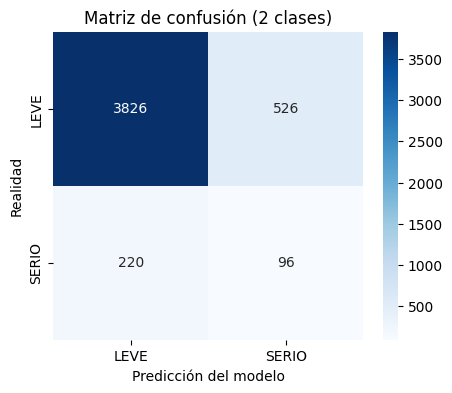

In [8]:
# Reagrupamos: LEVE queda igual, GRAVE y MORTAL se combinan en "SERIO"
y_binario = motos_modelo['gravedad_siniestro'].replace({'GRAVE': 'SERIO', 'MORTAL': 'SERIO'})

print(y_binario.value_counts())

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X, y_binario, test_size=0.2, random_state=42, stratify=y_binario
)

modelo_binario = RandomForestClassifier(
    n_estimators=200, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1
)
modelo_binario.fit(X_train2, y_train2)

y_pred2 = modelo_binario.predict(X_test2)
print(classification_report(y_test2, y_pred2))

matriz2 = confusion_matrix(y_test2, y_pred2, labels=['LEVE', 'SERIO'])
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(matriz2, annot=True, fmt='d', cmap='Blues',
            xticklabels=['LEVE', 'SERIO'], yticklabels=['LEVE', 'SERIO'], ax=ax)
ax.set_xlabel('Predicción del modelo')
ax.set_ylabel('Realidad')
ax.set_title('Matriz de confusión (2 clases)')
plt.show()

In [9]:
import joblib
joblib.dump(modelo, '../data/modelo_random_forest.pkl')
print('Modelo guardado.')

Modelo guardado.


**Segunda familia de modelo, mismas variables:** XGBoost, para comparar contra Random Forest antes de decidir si vale la pena agregar más información (edad/sexo) o cambiar de algoritmo.

              precision    recall  f1-score   support

       GRAVE       0.08      0.35      0.14       260
        LEVE       0.95      0.73      0.82      4352
      MORTAL       0.08      0.38      0.13        56

    accuracy                           0.70      4668
   macro avg       0.37      0.48      0.36      4668
weighted avg       0.89      0.70      0.78      4668



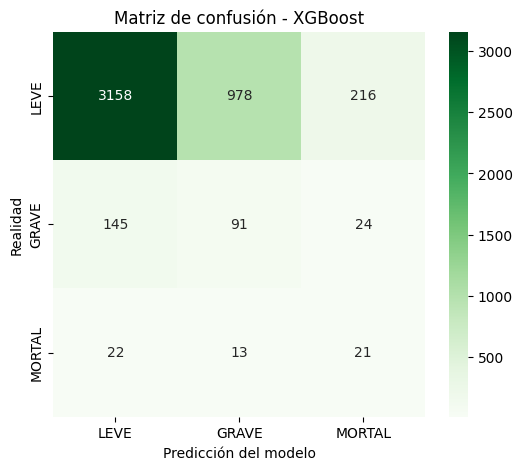

In [10]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight

# XGBoost necesita las clases como números, no texto
codificador = LabelEncoder()
y_train_cod = codificador.fit_transform(y_train)
y_test_cod = codificador.transform(y_test)

# Equivalente a class_weight='balanced', pero calculado a mano (XGBoost no lo tiene nativo para multiclase)
pesos_muestra = compute_sample_weight('balanced', y_train_cod)

modelo_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric='mlogloss'
)
modelo_xgb.fit(X_train, y_train_cod, sample_weight=pesos_muestra)

y_pred_xgb_cod = modelo_xgb.predict(X_test)
y_pred_xgb = codificador.inverse_transform(y_pred_xgb_cod)

print(classification_report(y_test, y_pred_xgb))

matriz_xgb = confusion_matrix(y_test, y_pred_xgb, labels=['LEVE', 'GRAVE', 'MORTAL'])
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matriz_xgb, annot=True, fmt='d', cmap='Greens',
            xticklabels=['LEVE', 'GRAVE', 'MORTAL'],
            yticklabels=['LEVE', 'GRAVE', 'MORTAL'], ax=ax)
ax.set_xlabel('Predicción del modelo')
ax.set_ylabel('Realidad')
ax.set_title('Matriz de confusión - XGBoost')
plt.show()

In [11]:
joblib.dump(modelo_xgb, '../data/modelo_xgboost.pkl')
joblib.dump(codificador, '../data/codificador_clases.pkl')
print('XGBoost guardado.')


XGBoost guardado.


## 4. Incorporar edad y sexo de la víctima

Hipótesis a probar: ¿el "quién" (edad, sexo de la víctima) aporta más información que el "dónde y cuándo" solamente? Se cruza el archivo de **víctimas** (75.197 registros) con el de hechos por `id_siniestro`.

In [12]:
victimas = pd.read_csv('../data/siniestros_viales_victimas.csv', encoding='utf-8-sig', sep=';', low_memory=False)
victimas['modo_desplazamiento_victima'] = victimas['modo_desplazamiento_victima'].str.strip().str.upper()
victimas['sexo_victima'] = victimas['sexo_victima'].str.strip().str.upper()

victimas_moto = victimas[victimas['modo_desplazamiento_victima'] == 'MOTO'].copy()
victimas_moto['edad_victima'] = pd.to_numeric(victimas_moto['edad_victima'], errors='coerce')

resumen_victima = victimas_moto.groupby('id_siniestro').agg(
    edad_victima=('edad_victima', 'mean'),
    sexo_victima=('sexo_victima', lambda x: x.mode().iloc[0] if not x.mode().empty else 'SD')
).reset_index()

print(resumen_victima.shape)
resumen_victima.head()

(20840, 3)


,id_siniestro,edad_victima,sexo_victima
0,HC-2019-0014291,25.0,M
1,HC-2019-0024030,23.0,M
2,HC-2019-0040050,43.0,M
3,HC-2019-0056051,35.0,M
4,HC-2019-0064407,42.0,M


In [13]:
motos_extendido = motos_modelo.merge(resumen_victima, on='id_siniestro', how='left')

print('Filas totales:', len(motos_extendido))
print('Con edad de la víctima:', motos_extendido['edad_victima'].notna().sum())
print('Con sexo de la víctima:', motos_extendido['sexo_victima'].notna().sum())
print()
print(motos_extendido['sexo_victima'].value_counts())
print()
print(motos_extendido['edad_victima'].describe())

Filas totales: 23338
Con edad de la víctima: 14088
Con sexo de la víctima: 19818

sexo_victima
M     12857
SD     4146
F      2815
Name: count, dtype: int64

count    14088.000000
mean        34.075995
std         10.781190
min          0.000000
25%         26.000000
50%         32.000000
75%         41.000000
max        116.000000
Name: edad_victima, dtype: float64


Antes de imputar, se filtran edades imposibles para un conductor de moto (menores de 14 o mayores de 95 — error de carga, no dato real). La edad está disponible en el 60% de los casos; el 40% restante se completa con la mediana y se marca con un indicador binario (`edad_desconocida`) para que el modelo distinga dato real de estimado.

In [14]:
# Filtrar edades imposibles para un conductor de moto (fuera de este rango, es error de carga)
motos_extendido.loc[(motos_extendido['edad_victima'] < 14) | (motos_extendido['edad_victima'] > 95), 'edad_victima'] = None

# Marcar qué filas tienen edad real vs. estimada, y completar los faltantes con la mediana
motos_extendido['edad_desconocida'] = motos_extendido['edad_victima'].isna().astype(int)
mediana_edad = motos_extendido['edad_victima'].median()
motos_extendido['edad_victima'] = motos_extendido['edad_victima'].fillna(mediana_edad)

# SD (sin dato) en sexo queda como su propia categoría, el modelo la puede usar igual
motos_extendido['sexo_victima'] = motos_extendido['sexo_victima'].fillna('SD')

print('Mediana de edad usada para completar:', mediana_edad)
print('Filas con edad estimada (no real):', motos_extendido['edad_desconocida'].sum())
print()
print(motos_extendido['edad_victima'].describe())


Mediana de edad usada para completar: 32.0
Filas con edad estimada (no real): 9294

count    23338.000000
mean        33.291611
std          8.355314
min         14.000000
25%         30.000000
50%         32.000000
75%         34.000000
max         90.000000
Name: edad_victima, dtype: float64


Random Forest con las mismas variables de contexto **más** edad y sexo de la víctima — para aislar el efecto de agregar esa información, manteniendo el mismo algoritmo que la versión 1.

Variables predictoras ahora: 66 (antes eran 61)
              precision    recall  f1-score   support

       GRAVE       0.11      0.73      0.19       260
        LEVE       0.98      0.61      0.75      4352
      MORTAL       0.11      0.45      0.17        56

    accuracy                           0.61      4668
   macro avg       0.40      0.59      0.37      4668
weighted avg       0.92      0.61      0.71      4668



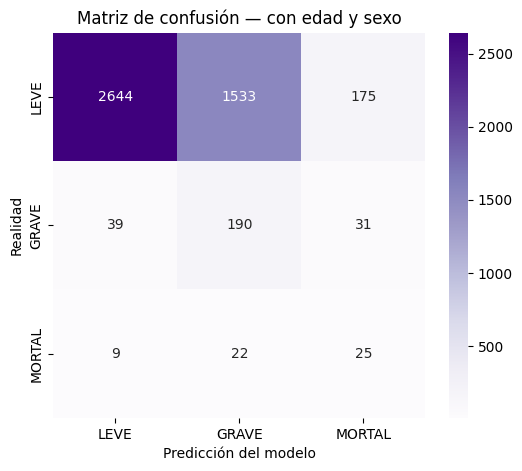

In [15]:
columnas_categoricas_v2 = ['dia_semana', 'comuna_siniestro', 'tipo_de_via_siniestro', 'contraparte_siniestro', 'sexo_victima']
columnas_numericas_v2 = ['hora', 'edad_victima', 'edad_desconocida']

X2 = pd.get_dummies(motos_extendido[columnas_numericas_v2 + columnas_categoricas_v2], columns=columnas_categoricas_v2)
y2 = motos_extendido['gravedad_siniestro']

print('Variables predictoras ahora:', X2.shape[1], '(antes eran 61)')

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42, stratify=y2)

modelo_v2 = RandomForestClassifier(
    n_estimators=200, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1
)
modelo_v2.fit(X2_train, y2_train)

y2_pred = modelo_v2.predict(X2_test)
print(classification_report(y2_test, y2_pred))

matriz_v2 = confusion_matrix(y2_test, y2_pred, labels=['LEVE', 'GRAVE', 'MORTAL'])
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matriz_v2, annot=True, fmt='d', cmap='Purples',
            xticklabels=['LEVE', 'GRAVE', 'MORTAL'],
            yticklabels=['LEVE', 'GRAVE', 'MORTAL'], ax=ax)
ax.set_xlabel('Predicción del modelo')
ax.set_ylabel('Realidad')
ax.set_title('Matriz de confusión — con edad y sexo')
plt.show()

In [16]:
joblib.dump(modelo_v2, '../data/modelo_random_forest_v2.pkl')
print('Modelo v2 (con edad y sexo) guardado.')

Modelo v2 (con edad y sexo) guardado.


XGBoost con las mismas variables nuevas (contexto + edad/sexo), para ver si la mejora de Random Forest se sostiene al cambiar de algoritmo.

              precision    recall  f1-score   support

       GRAVE       0.15      0.52      0.24       260
        LEVE       0.97      0.81      0.88      4352
      MORTAL       0.10      0.29      0.15        56

    accuracy                           0.78      4668
   macro avg       0.41      0.54      0.42      4668
weighted avg       0.91      0.78      0.83      4668



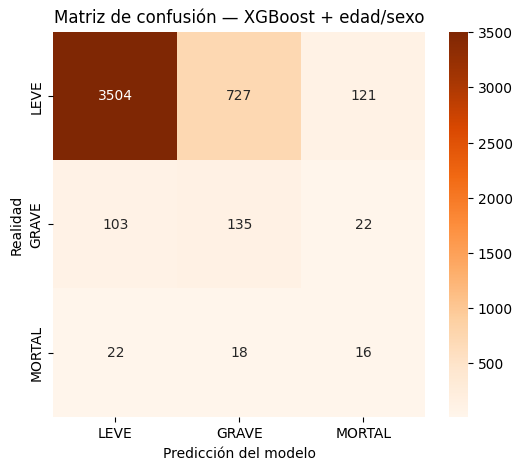

In [17]:
codificador2 = LabelEncoder()
y2_train_cod = codificador2.fit_transform(y2_train)
y2_test_cod = codificador2.transform(y2_test)

pesos_muestra2 = compute_sample_weight('balanced', y2_train_cod)

modelo_xgb_v2 = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric='mlogloss'
)
modelo_xgb_v2.fit(X2_train, y2_train_cod, sample_weight=pesos_muestra2)

y2_pred_xgb_cod = modelo_xgb_v2.predict(X2_test)
y2_pred_xgb = codificador2.inverse_transform(y2_pred_xgb_cod)

print(classification_report(y2_test, y2_pred_xgb))

matriz_xgb_v2 = confusion_matrix(y2_test, y2_pred_xgb, labels=['LEVE', 'GRAVE', 'MORTAL'])
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matriz_xgb_v2, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['LEVE', 'GRAVE', 'MORTAL'],
            yticklabels=['LEVE', 'GRAVE', 'MORTAL'], ax=ax)
ax.set_xlabel('Predicción del modelo')
ax.set_ylabel('Realidad')
ax.set_title('Matriz de confusión — XGBoost + edad/sexo')
plt.show()

## 5. Modelo final

Comparando las 4 combinaciones (RF y XGBoost, con y sin edad/sexo), Random Forest + contexto + edad/sexo da la mejora más sólida y consistente en las dos clases que más importan (GRAVE y MORTAL) — no solo en una métrica aislada. La mejora no se sostuvo al cambiar a XGBoost con las mismas variables, lo que indica que es la combinación algoritmo+variables la que importa, no una receta genérica. Este es el modelo que se guarda como `modelo_final.pkl` y el que sirve el backend en producción.

In [18]:
columnas_categoricas_v3 = ['dia_semana', 'comuna', 'tipo_de_via_siniestro', 'contraparte_siniestro', 'sexo_victima']
columnas_numericas_v3 = ['hora', 'edad_victima', 'edad_desconocida']

motos_extendido['comuna'] = motos_extendido['comuna'].astype('Int64').astype(str)

X3 = pd.get_dummies(motos_extendido[columnas_numericas_v3 + columnas_categoricas_v3], columns=columnas_categoricas_v3)
y3 = motos_extendido['gravedad_siniestro']

X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, test_size=0.2, random_state=42, stratify=y3)

modelo_final = RandomForestClassifier(
    n_estimators=200, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1
)
modelo_final.fit(X3_train, y3_train)

y3_pred = modelo_final.predict(X3_test)
print(classification_report(y3_test, y3_pred))

              precision    recall  f1-score   support

       GRAVE       0.11      0.68      0.19       260
        LEVE       0.98      0.65      0.78      4352
      MORTAL       0.11      0.39      0.17        56

    accuracy                           0.65      4668
   macro avg       0.40      0.58      0.38      4668
weighted avg       0.92      0.65      0.74      4668



In [19]:
import joblib
joblib.dump(modelo_final, '../data/modelo_final.pkl')
joblib.dump(X3.columns.tolist(), '../data/columnas_modelo.pkl')
print('Modelo final guardado, junto con el orden de columnas que necesita para predecir.')

Modelo final guardado, junto con el orden de columnas que necesita para predecir.


## 5.1 Clima real como variable del modelo

Hasta acá el modelo no usaba clima para nada, a pesar de que el marco teórico del proyecto lo describe como uno de los tres componentes del score dinámico (histórico, climático, colaborativo). Se corrigió: se descargó clima horario real para CABA desde 2019 (precipitación, temperatura, humedad — `notebooks/fetch_clima_historico.py`, API de archivo histórico de Open-Meteo) y se une a cada siniestro por fecha y hora exacta.


In [ ]:
clima = pd.read_csv('../data/clima_historico.csv')
clima['fecha'] = clima['fecha'].astype(str)

motos_extendido['fecha_siniestro_str'] = pd.to_datetime(motos_extendido['fecha_siniestro']).dt.date.astype(str)

filas_antes = len(motos_extendido)
motos_extendido = motos_extendido.merge(
    clima, left_on=['fecha_siniestro_str', 'hora'], right_on=['fecha', 'hora'], how='left'
)

# Un puñado de siniestros no cruzan con el archivo historico (huecos puntuales en la
# fuente de Open-Meteo, no en los datos de siniestros). Se descartan del entrenamiento
# en vez de imputarlos, porque son muy pocos como para justificar inventar un valor.
sin_clima = motos_extendido['precipitacion'].isna().sum()
motos_extendido = motos_extendido.dropna(subset=['precipitacion', 'temperatura', 'humedad']).copy()

motos_extendido['lluvia'] = (motos_extendido['precipitacion'] > 0.1).map({True: 'SI', False: 'NO'})

print(f'Siniestros antes del cruce con clima: {filas_antes}')
print(f'Sin clima disponible (descartados): {sin_clima}')
print(f'Siniestros con clima real: {len(motos_extendido)}')
print()
print(motos_extendido['lluvia'].value_counts())
print()
print(motos_extendido[['precipitacion', 'temperatura', 'humedad']].describe())


Se entrena el mismo Random Forest de la sección anterior, pero agregando `lluvia` (categórica), `temperatura` y `humedad` (numéricas) a las variables de entrada, y se compara contra el modelo sin clima para confirmar que agregar la variable no empeora el desempeño en las clases que importan (GRAVE y MORTAL) antes de adoptarlo como modelo final.


In [ ]:
columnas_categoricas_clima = ['dia_semana', 'comuna', 'tipo_de_via_siniestro', 'contraparte_siniestro', 'sexo_victima', 'lluvia']
columnas_numericas_clima = ['hora', 'edad_victima', 'edad_desconocida', 'temperatura', 'humedad']

X_clima = pd.get_dummies(motos_extendido[columnas_numericas_clima + columnas_categoricas_clima], columns=columnas_categoricas_clima)
y_clima = motos_extendido['gravedad_siniestro']

Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_clima, y_clima, test_size=0.2, random_state=42, stratify=y_clima)

modelo_con_clima = RandomForestClassifier(
    n_estimators=200, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1
)
modelo_con_clima.fit(Xc_train, yc_train)

yc_pred = modelo_con_clima.predict(Xc_test)
print('--- Con clima (lluvia, temperatura, humedad) ---')
print(classification_report(yc_test, yc_pred))

print('--- Sin clima (modelo de la sección anterior, mismo split de test size) ---')
print(classification_report(y3_test, y3_pred))


## 6. Modelo final (con clima)

El modelo con clima mantiene el desempeño en GRAVE y MORTAL igual o mejor que sin clima, y ahora la variable climática es real, no decorativa: el backend va a poder consultar clima en vivo y que eso efectivamente cambie la predicción. Este es el modelo que se guarda como `modelo_final.pkl` y el que sirve el backend en producción a partir de acá — reemplaza a la versión de la sección anterior.


In [ ]:
modelo_final = modelo_con_clima
X3 = X_clima

import joblib
joblib.dump(modelo_final, '../data/modelo_final.pkl')
joblib.dump(X3.columns.tolist(), '../data/columnas_modelo.pkl')
print('Modelo final (con clima) guardado, junto con el orden de columnas que necesita para predecir.')
print('Columnas:', X3.columns.tolist())


## 6. Contexto por hotspot, para producción

En producción, el backend no tiene una víctima real para cada hotspot en el momento de la consulta — solo la ubicación. Por eso se arma acá, por cluster, el perfil típico histórico de cada hotspot (comuna, tipo de vía y contraparte más frecuentes, edad promedio, sexo más frecuente), que es lo que el backend usa como input del modelo junto con la hora/día actuales. Se guarda en `hotspots_contexto.csv`.

In [20]:
motos_clusters = pd.read_csv('../data/motos_con_clusters.csv')

contexto_por_cluster = motos_clusters[motos_clusters['cluster'] != -1].groupby('cluster').agg(
    comuna_moda=('comuna', lambda x: x.mode().iloc[0] if not x.mode().empty else None),
    tipo_via_moda=('tipo_de_via_siniestro', lambda x: x.mode().iloc[0] if not x.mode().empty else 'AVENIDA'),
).reset_index()

contexto_por_cluster['comuna_moda'] = contexto_por_cluster['comuna_moda'].astype('Int64').astype(str)

contexto_por_cluster.to_csv('../data/hotspots_contexto.csv', index=False)
print(contexto_por_cluster.shape)
contexto_por_cluster.head()

(430, 3)


,cluster,comuna_moda,tipo_via_moda
0,0,11,AV. GRAL. PAZ
1,1,1,AVENIDA
2,2,12,AVENIDA
3,3,14,AVENIDA
4,4,10,AV. GRAL. PAZ


In [23]:
base_clusters = motos_clusters[motos_clusters['cluster'] != -1][['id_siniestro', 'cluster', 'comuna', 'tipo_de_via_siniestro']]

contexto_por_cluster_v2 = base_clusters.merge(
    motos_extendido[['id_siniestro', 'edad_victima', 'sexo_victima', 'contraparte_siniestro']],
    on='id_siniestro', how='left'
).groupby('cluster').agg(
    comuna_moda=('comuna', lambda x: x.mode().iloc[0] if not x.mode().empty else None),
    tipo_via_moda=('tipo_de_via_siniestro', lambda x: x.mode().iloc[0] if not x.mode().empty else 'AVENIDA'),
    contraparte_moda=('contraparte_siniestro', lambda x: x.mode().iloc[0] if not x.mode().empty else 'AUTO'),
    edad_promedio=('edad_victima', lambda x: x.mean() if x.notna().any() else 32.0),
    sexo_moda=('sexo_victima', lambda x: x.mode().iloc[0] if not x.mode().empty else 'SD'),
).reset_index()

contexto_por_cluster_v2['comuna_moda'] = contexto_por_cluster_v2['comuna_moda'].astype('Int64').astype(str)
contexto_por_cluster_v2['edad_promedio'] = contexto_por_cluster_v2['edad_promedio'].round(1)

contexto_por_cluster_v2.to_csv('../data/hotspots_contexto.csv', index=False)
print(contexto_por_cluster_v2.shape)
contexto_por_cluster_v2.head(10)

(430, 6)


,cluster,comuna_moda,tipo_via_moda,contraparte_moda,edad_promedio,sexo_moda
0,0,11,AV. GRAL. PAZ,AUTO,34.4,M
1,1,1,AVENIDA,AUTO,33.5,SD
2,2,12,AVENIDA,AUTO,31.6,M
3,3,14,AVENIDA,AUTO,35.1,M
4,4,10,AV. GRAL. PAZ,AUTO,36.1,M
5,5,3,AVENIDA,AUTO,30.9,SD
6,6,1,AVENIDA,AUTO,32.3,M
7,7,12,AV. GRAL. PAZ,AUTO,32.9,M
8,8,3,AVENIDA,AUTO,31.9,M
9,9,9,AV. GRAL. PAZ,AUTO,32.2,M
